In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# import nested_pandas as npd

%matplotlib inline

In [2]:
from rubin_sim.maf.metrics.mdwarf_flares_metrics import (
    MDwarfCountMetric,
    MDwarfMeasureMetric,
)
from rubin_sim.maf import slicers
from rubin_sim.maf import metricBundles
from rubin_sim.maf import db

/Users/wickcedar/miniconda3/envs/lcl/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from lightcurvelynx.obstable.opsim import OpSim
from lightcurvelynx.survey_info import SurveyInfo
from lightcurvelynx.models.mdwarf_flare_model import MDwarfFlareModel
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.simulate import (
    compute_single_noise_free_lightcurve,
    simulate_lightcurves,
)
from lightcurvelynx.utils.post_process_results import results_augment_lightcurves
from lightcurvelynx.utils.plotting import plot_lightcurves
from lightcurvelynx.graph_state import GraphState
from lightcurvelynx.math_nodes.ra_dec_sampler import (
    ApproximateMOCSampler)

/Users/wickcedar/miniconda3/envs/oldpython/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Running M Dwarf Flares Metrics with MAF and LightCurveLynx

This notebook walks through simulating M Dwarf Flares with LightCurveLynx and using that output to compute the MAF M Dwarf Flares metrics.

There are two M Dwarf Flare metrics which tally how many M Dwarf Flares are detected by the LSST. The first, the "Count" metric, only requires one observation to consider a flare to be detected. The second, the "Measure" metric, follows Hilton 2011 in requiring three observations (2 above 3 sigma, 1 above 5 sigma) to confirm the presence of a flare.

The M Dwarf Flare metrics use the flare model built in to LightCurveLynx and the LCL slicer that reads LCL output. This notebook begins with creating the LCL output.

## Simulating Flares in LightCurveLynx

First, we set up the opsim for LCL:

In [3]:
opsim_url = "https://s3df.slac.stanford.edu/data/rubin/sim-data\
    /sims_featureScheduler_runs5.3/baseline/baseline_v5.3.0_10yrs.db"

# Uncomment the following line to load data from a URL
ops_data = OpSim.from_url(opsim_url, use_detector_footprint="lsst")

# Alternatively if you are using a local OpSim with a known file path,
# you can use from_db() or from_parquet() to read it directly.

/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/obstable/obs_table.py:197: UserWarning: Column 'scheduler_note' has more than 100 unique string values. We are skipping the conversion to categorical. This may impact performance and memory usage with parallel computation. Consider dropping this column if it is not needed for your analysis.
  warnings.warn(
/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/obstable/obs_table.py:197: UserWarning: Column 'target_name' has more than 100 unique string values. We are skipping the conversion to categorical. This may impact performance and memory usage with parallel computation. Consider dropping this column if it is not needed for your analysis.
  warnings.warn(
/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/obstable/obs_table.py:197: UserWarning: Column 'observation_reason' has more than 100 unique string values. We are skipping the conversion to categorical. This may impact performance and memory usage with parallel computation. Consi

In [4]:
ops_data.head()

,observationId,ra,dec,time,flush_by_mjd,exptime,band,filter,rotation,rotSkyPos_desired,...,moonDistance,solarElong,moonPhase,cummTelAz,observation_reason,science_program,cloud_extinction,zp,psf_footprint,sky_bg_e
0,0,266.377911,-45.894524,61208.201382,61208.255938,38.0,u,u,278.404669,0.0,...,147.083478,157.452826,16.210877,-179.137913,template_blob_uu_25.0,BLOCK-419,0.0,2.386006,41.765721,50.658052
1,1,262.574865,-46.941452,61208.201933,61208.255938,38.0,u,u,289.642367,0.0,...,144.274292,156.323709,16.216452,-170.506774,template_blob_uu_25.0,BLOCK-419,0.0,2.393835,42.140785,50.507657
2,2,266.039362,-49.016651,61208.202483,61208.255938,38.0,u,u,279.140130,0.0,...,145.200492,154.341310,16.222024,-179.031250,template_blob_uu_25.0,BLOCK-419,0.0,2.404088,42.630972,50.274301
3,3,261.992377,-50.037844,61208.203025,61208.255938,38.0,u,u,289.266344,0.0,...,142.425648,153.203529,16.227522,-171.793078,template_blob_uu_25.0,BLOCK-419,0.0,2.413818,43.095059,50.145802
4,4,265.679819,-52.132077,61208.203568,61208.255938,38.0,u,u,279.725930,0.0,...,143.183649,151.231294,16.233029,-179.147649,template_blob_uu_25.0,BLOCK-419,0.0,2.426261,30.840128,49.924925


For M Dwarf Flares, we only care about observations in u, g, or r, so we are filtering out the LSST visits that are not in those bands.

In [5]:
mask = ops_data["band"].isin(["u", "g", "r"])

In [6]:
survey_info = SurveyInfo(obstable=ops_data.filter_rows(mask), survey_name="LSST")

We're only going to simulate M Dwarf Flares in the region of the sky that is accessible by the LSST, so we use an [MOC](https://lightcurvelynx.readthedocs.io/en/latest/notebooks/sampling_positions.html ) to feed into our spatial distributions.

In [7]:
moc = ops_data.build_moc()

### Create Parameter Distributions

The M Dwarf Flare model has built-in priors based on TESS flare observations for the following parameters: star temperature, star radius, flare amplitude, and flare full width half max.

It will also draw distances, RAs, and Decs from a Galactic distribution. 

We must choose the total number of flares, which for now will be 100000 but should be XXYY over the whole survey (i think it's something like the number of m dwarfs in the galaxy and we assume one flare per year).

We use obs_time_window_offset to only simulate m dwarf flares for the period around which they are flaring, to avoid the unnecessary computation of simulating the star's static existence for the other 9.99 years. Later, we will also simulating observations for the year before the flare in order to compare the quiescent flux to the flare's flux.

In [8]:
# flare peak times - random throughout whole survey
flare_peak_time_sampler = NumpyRandomFunc(
    "uniform", low=np.min(ops_data["time"]), high=np.max(ops_data["time"])
)

In [9]:
model = MDwarfFlareModel(t0=flare_peak_time_sampler, MOC=moc)

In [39]:
# Fix the random seed to make it reproducible.
rng = np.random.default_rng(42)

#choose your number of m dwarfs to simulate
num_samples=1000

#simulate
df_1 = simulate_lightcurves(
    model=model,
    num_samples=num_samples,
    survey_info=survey_info,
    rng=rng,
    obs_time_window_offset=(-.5, 1.5),
    drop_empty_rows=True,  # Drop objects we don't see at all.

)

# if you want to view df,
# keep params separate because it is quite large:
params = df_1["params"].copy()
df_1 = df_1.drop(columns=["params"])

# to view params as an astropy table:
# state = GraphState.from_list(params)
# params_table = state.to_table()

Simulating: 100%|████████████████████████| 1000/1000 [00:05<00:00, 196.93obj/s]


First, let's check how many were observed within our time window (currently -.5 to 1.5 days from peak, since M dwarf flares occur over minutes-hours)

In [26]:
print("total number: ",len(df_1))
print("fraction within time window: ", len(df_1)/num_samples)

total number:  78
fraction within time window:  0.078


And we can look at a couple of them. It will become obvious that just because they are within our time window does not mean that they have been detected in a useable way.

/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/astro_utils/mag_flux.py:62: RuntimeWarning: invalid value encountered in log10
  mag = MAG_AB_ZP_NJY - 2.5 * np.log10(flux_njy)


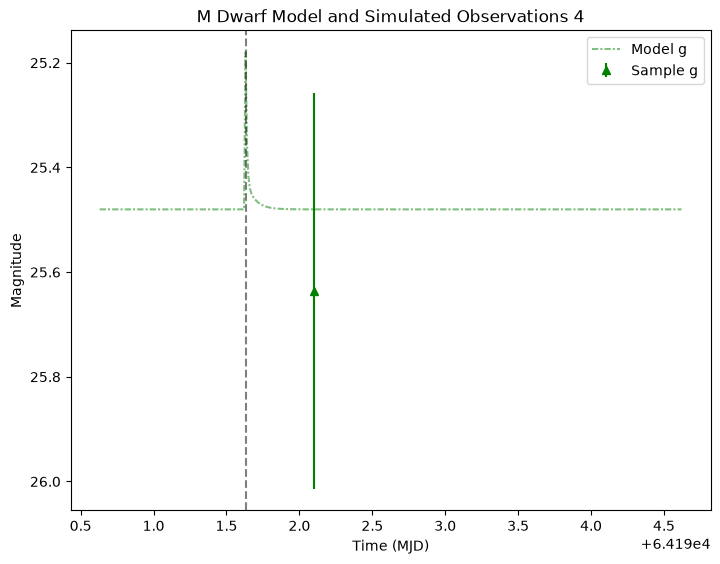

/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/astro_utils/mag_flux.py:62: RuntimeWarning: invalid value encountered in log10
  mag = MAG_AB_ZP_NJY - 2.5 * np.log10(flux_njy)


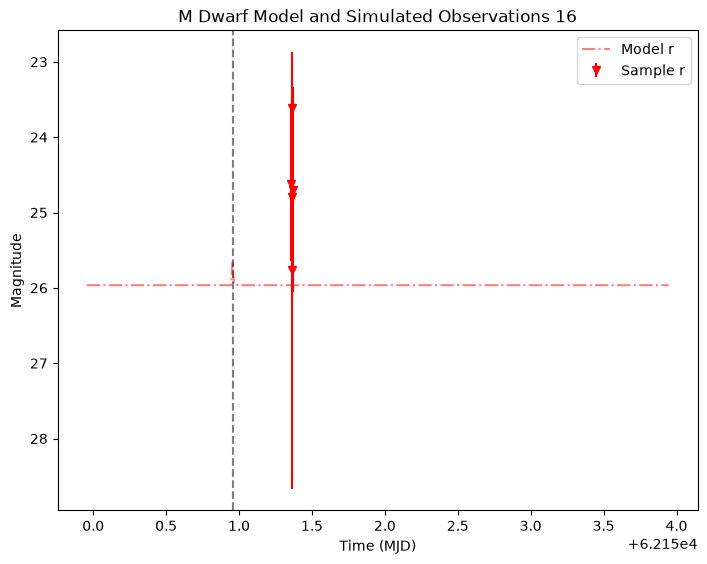

In [58]:
for i in range(2):
    idx = df_1.iloc[i]['id'] 
    # Extract the row for this object.
    row = df_1.loc[idx]
    lc = row["lightcurve"]

    # Extract the parameters used during the simulation of this object. Use that to
    # compute the noise-free light curve for this object, which we will plot alongside
    # the simulated light curve.
    noise_free_lcs = compute_single_noise_free_lightcurve(
        model,
        GraphState.from_dict(params[idx]),
        survey_info.passbands,
        rest_frame_phase_min=-1,
        rest_frame_phase_max=3,
        rest_frame_phase_step=0.01,
    )

    plot_lightcurves(
        fluxes=lc["flux"],
        times=lc["mjd"],
        fluxerrs=lc["fluxerr"],
        filters=lc["filter"],
        underlying_model=noise_free_lcs,
        plot_magnitudes=True,
    )

    # Plot a vertical line at t0, which is the reference time for the light curve.
    plt.axvline(
        x=params[idx]["MDwarfFlareModel_0.t0"], color="k", linestyle="--", alpha=0.5
    )
    # plt.xlim(params[idx]["MDwarfFlareModel_0.t0"]-10, params[idx]["MDwarfFlareModel_0.t0"]+15)
    # plt.ylim(29,22)
    plt.title("M Dwarf Model and Simulated Observations " + str(idx))
    plt.legend()
    plt.show()

Now, we only want to simulate these flares that are observed during our time window, but we want the past year's worth of observations so that we can compare them to their quiescent flux. So, we extract the parameters for these objects (including positions and `t0` and use that to simulate those objects) for a previous year.

In [59]:
# Extract the parameters of the unfiltered objects.
states = GraphState.from_list(params.to_numpy())

# Resimulate for a year. We don't set rng here, because we are replaying from state.
df = simulate_lightcurves(
    model=model,
    graph_state=states,  # Simulate from the saved parameters
    num_samples=states.num_samples,
    survey_info=survey_info,
    obs_time_window_offset=(-365, 1.5),
)
# keep params separate because it is quite large:
params = df["params"].copy()
df = df.drop(columns=["params"])

# compute snr column, etc
lc_augmented = results_augment_lightcurves(df)  

Simulating: 100%|█████████████████████████████| 78/78 [00:06<00:00, 11.78obj/s]


Let's look at a few of these observations!


/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/astro_utils/mag_flux.py:62: RuntimeWarning: invalid value encountered in log10
  mag = MAG_AB_ZP_NJY - 2.5 * np.log10(flux_njy)


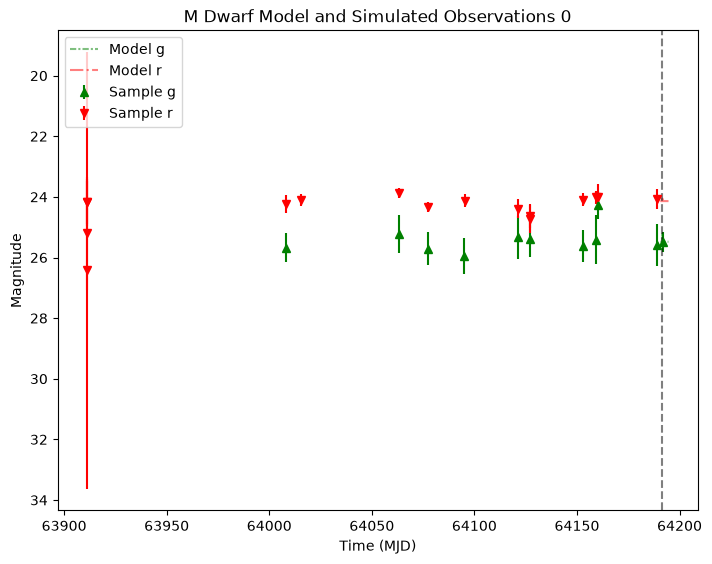

/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/astro_utils/mag_flux.py:62: RuntimeWarning: invalid value encountered in log10
  mag = MAG_AB_ZP_NJY - 2.5 * np.log10(flux_njy)


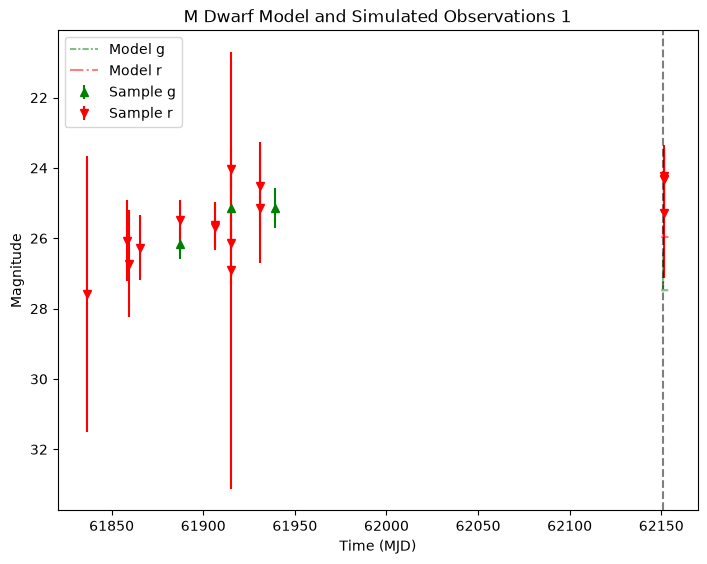

/Users/wickcedar/lightcurvelynx/src/lightcurvelynx/astro_utils/mag_flux.py:62: RuntimeWarning: invalid value encountered in log10
  mag = MAG_AB_ZP_NJY - 2.5 * np.log10(flux_njy)


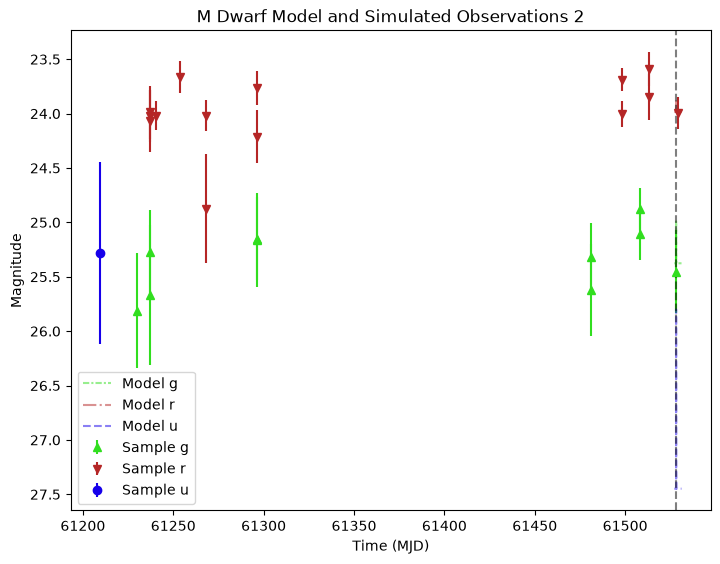

In [60]:
for i in range(3):
    idx = df.iloc[i]['id'] 
    # Extract the row for this object.
    row = lc_augmented.loc[idx]
    lc = row["lightcurve"]

    # Extract the parameters used during the simulation of this object. Use that to
    # compute the noise-free light curve for this object, which we will plot alongside
    # the simulated light curve.
    noise_free_lcs = compute_single_noise_free_lightcurve(
        model,
        GraphState.from_dict(params[idx]),
        survey_info.passbands,
        rest_frame_phase_min=-1,
        rest_frame_phase_max=3,
        rest_frame_phase_step=0.01,
    )

    plot_lightcurves(
        fluxes=lc["flux"],
        times=lc["mjd"],
        fluxerrs=lc["fluxerr"],
        filters=lc["filter"],
        underlying_model=noise_free_lcs,
        plot_magnitudes=True,
    )

    # Plot a vertical line at t0, which is the reference time for the light curve.
    plt.axvline(
        x=params[idx]["MDwarfFlareModel_0.t0"], color="k", linestyle="--", alpha=0.5
    )
    # plt.xlim(params[idx]["MDwarfFlareModel_0.t0"]-10, params[idx]["MDwarfFlareModel_0.t0"]+15)
    # plt.ylim(29,22)
    plt.title("M Dwarf Model and Simulated Observations " + str(idx))
    plt.legend()
    plt.show()

Now we save the lc and the files for loading into MAF.

In [61]:
YOUR_DATA_PATH = "/Users/wickcedar/maf_runs/"

In [62]:
lc_augmented.to_parquet(os.path.join(YOUR_DATA_PATH, "my_results.parquet"))
params.to_csv(os.path.join(YOUR_DATA_PATH, "my_params.csv"))

## Running MAF on the LCL output

We will use this function which uses the LynxBaseSlicer to handle the parquet file. Results are written to your data path.

In [4]:
def run_lightcurvelynx(sim_data, metric):
    out_dir = YOUR_DATA_PATH
    slicer = slicers.LynxBaseSlicer()
    metric = metric(col="lightcurve")

    bundle = metricBundles.MetricBundle(metric, slicer, constraint="")

    results_db = db.ResultsDb(out_dir=out_dir)

    group = metricBundles.MetricBundleGroup(
        [bundle],
        sim_data,
        out_dir=out_dir,
        results_db=results_db,
        db_table="lightcurves",
    )

    group.run_all()

In [5]:
run_lightcurvelynx(
    os.path.join(YOUR_DATA_PATH, "my_results_slim.parquet"), MDwarfCountMetric
)

Your results will live in your data path as well. Let's see how many of our M Dwarf Flares were detected:

In [6]:
results_file = np.load(
    os.path.join(YOUR_DATA_PATH, "run_name_MDwarfCount_lightcurve_LYNX.npz"),
    allow_pickle=True
)

In [7]:
pd.DataFrame(list(results_file["metric_values"])) 

,metric_value,first_true_band,pre_flare_average
0,False,None,None
1,False,None,None
...,...,...,...
903,False,None,None
904,False,None,None


In [8]:
np.sum(pd.DataFrame(list(results_file["metric_values"])) ["metric_value"])

np.int64(0)

You can view the params associated with an observation by indexing your previously-saved params

In [8]:
my_params = pd.read_csv(os.path.join(YOUR_DATA_PATH, "my_params.csv"))

In [10]:
# Use this to check out the light curve if you detect anything
# np.where(results_file['metric_values'])[0][0]
# my_results.loc[np.where(results_file['metric_values'])[0][0]]['lightcurve']
# and the params:
# my_params.loc[np.where(results_file['metric_values'])[0][0]]['params']

The goal here is to pass m dwarf flares that were successfully detected in the first metric into the second metric (the second metric does not need to see anything that was not detected), by just re-saving a new parquet file.

Currently there are no detections from the first file. But this is what that would look like:

In [ ]:
#save smaller file
#(this needs checking once we have a file to check it with)

import nested_pandas as npd
lcs = npd.read_parquet(os.path.join(YOUR_DATA_PATH, "my_results_slim.parquet"))
lcs[pd.DataFrame(list(
    results_file["metric_values"]))["metric_value"]==True].to_parquet(
    os.path.join(YOUR_DATA_PATH, "my_detected_results.parquet"))


In [ ]:
run_lightcurvelynx(
    os.path.join(YOUR_DATA_PATH, "my_detected_results.parquet"), 
    MDwarfMeasureMetric
)

In [ ]:
results_file = np.load(
    os.path.join(YOUR_DATA_PATH, "run_name_MDwarfMeasure_lightcurve_LYNX.npz"),
    allow_pickle=True
)

In [ ]:
#see how many meet the criteria of this metric
np.sum(pd.DataFrame(list(results_file["metric_values"])) ["metric_value"])